# DirectLiNGAM with Multiscale Bootstrap

## Import and settings
In this example, we need to import `numpy`, `pandas`, and `graphviz` in addition to `lingam`.

In [1]:
import os
import numpy as np
import pandas as pd
import graphviz
import lingam
from lingam.utils import make_dot

print([np.__version__, pd.__version__, graphviz.__version__, lingam.__version__])

np.set_printoptions(precision=3, suppress=True)
np.random.seed(100)

['2.2.6', '3.0.6', '0.21', '1.13.0']


### Source code of multiscale bootstrap

We use the `pyscaleboot` package of this repository to run the multiscale bootstrap. It runs the bootstrap with several resample sizes and computes the AU / SI p-values with the R package `scaleboot`. The repository root (the parent directory of `examples`) is added to the import path, so run this notebook in the `examples` directory. The R and scaleboot packages must be installed manually.

In [2]:
import sys

# the repository root containing `pyscaleboot`
repository_root = os.path.abspath(os.pardir)
if repository_root not in sys.path:
    sys.path.insert(0, repository_root)

from pyscaleboot import (
    MultiScaleBootstrap,
    EdgeHypothesis,
    GraphHypothesis,
    RScalebootClient,
    build_scaleboot_input,
)

## Test data
We create test data consisting of 6 variables.

In [3]:
x3 = np.random.uniform(size=1000)
x0 = 3.0*x3 + np.random.uniform(size=1000)
x2 = 6.0*x3 + np.random.uniform(size=1000)
x1 = 3.0*x0 + 2.0*x2 + np.random.uniform(size=1000)
x5 = 4.0*x0 + np.random.uniform(size=1000)
x4 = 8.0*x0 - 1.0*x2 + np.random.uniform(size=1000)
X = pd.DataFrame(np.array([x0, x1, x2, x3, x4, x5]).T ,columns=['x0', 'x1', 'x2', 'x3', 'x4', 'x5'])
X.head()

,x0,x1,x2,x3,x4,x5
0,1.657947,12.090323,3.519873,0.543405,10.182785,7.401408
1,1.217345,7.607388,1.693219,0.278369,8.758949,4.912979
2,2.226804,13.483555,3.201513,0.424518,15.398626,9.098729
3,2.756527,20.654225,6.037873,0.844776,16.795156,11.147294
4,0.319283,3.340782,0.727265,0.004719,2.343100,2.037974


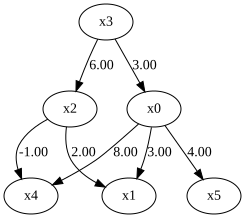

In [4]:
m = np.array([[0.0, 0.0, 0.0, 3.0, 0.0, 0.0],
              [3.0, 0.0, 2.0, 0.0, 0.0, 0.0],
              [0.0, 0.0, 0.0, 6.0, 0.0, 0.0],
              [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
              [8.0, 0.0,-1.0, 0.0, 0.0, 0.0],
              [4.0, 0.0, 0.0, 0.0, 0.0, 0.0]])

dot = make_dot(m)
dot

## Causal Discovery
To run causal discovery, we create a `DirectLiNGAM` object and call the `fit` method.

In [5]:
model = lingam.DirectLiNGAM()
model.fit(X)

Using the `causal_order_` properties, we can see the causal ordering as a result of the causal discovery.

In [6]:
model.causal_order_

[np.int64(3), np.int64(0), np.int64(2), np.int64(1), np.int64(4), np.int64(5)]

Also, using the `adjacency_matrix_` properties, we can see the adjacency matrix as a result of the causal discovery.

In [7]:
model.adjacency_matrix_

array([[ 0.   ,  0.   ,  0.   ,  2.994,  0.   ,  0.   ],
       [ 2.995,  0.   ,  1.993,  0.   ,  0.   ,  0.   ],
       [ 0.   ,  0.   ,  0.   ,  5.957,  0.   ,  0.   ],
       [ 0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ],
       [ 7.998,  0.   , -1.005,  0.   ,  0.   ,  0.   ],
       [ 3.98 ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ]])

We can draw a causal graph by utility function.

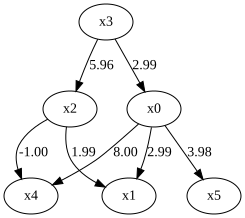

In [8]:
make_dot(model.adjacency_matrix_)

## Multiscale Bootstrap

The ordinary bootstrap estimates the bootstrap probability (BP) of a hypothesis, such as the existence of an edge, with resamples of the original size `n`. The multiscale bootstrap repeats it with several resample sizes `n'` and observes how BP changes with the scale `sa = n / n'`. From this change, the R package `scaleboot` computes the AU (approximately unbiased) p-value, which corrects the bias of BP, and the SI (selective inference) p-value, which takes into account that the hypothesis is selected from the data.

We use the `pyscaleboot` package of this repository in four steps: `MultiScaleBootstrap` runs the bootstrap on several scales, `EdgeHypothesis` and `GraphHypothesis` extract hypotheses and their BP, `RScalebootClient` converts BP to AU / SI p-values, and then we read the results. `Rscript` and the R package `scaleboot` are required.

### Settings

The package's public API has already been imported in the setup cell above. The following settings configure the multiscale bootstrap.

`SCALE_RATIOS` are the ratios `n' / n` of the resample sizes, and `N_BOOTSTRAP` is the number of resamples for each scale. `MIN_CAUSAL_EFFECT` is the minimum absolute coefficient regarded as a directed edge, and `SCALEBOOT_MODELS` are the candidate models of `scaleboot`.

The bootstrap is run only once. The AU / SI p-values are then calculated from the same BP table for each condition in `SCALEBOOT_CONDITIONS`. The conditions differ only in the arguments of `scaleboot`: `models` are the candidate models, and `select` specifies how their p-values are combined (`"average"` averages the p-values of the models, which is the default of `scaleboot`, and `"best"` takes the p-values of the model with the smallest AIC).

In [9]:
SCALE_RATIOS = (0.5, 0.7, 1.0, 1.4, 2.0)  # n' / n
N_BOOTSTRAP = 100  # number of resamples for each scale
MIN_CAUSAL_EFFECT = 0.01
SCALEBOOT_MODELS = ("poly.1", "poly.2", "poly.3", "sing.3", "sphe.3")  # default of scaleboot
# conditions of the scaleboot arguments; the bootstrap itself is run only once
SCALEBOOT_CONDITIONS = {
    "ave": dict(models=SCALEBOOT_MODELS, select="average"),
    "best": dict(models=SCALEBOOT_MODELS, select="best"),
    "poly1": dict(models=("poly.1",), select="average"),
}
RANDOM_STATE = 0

### Run multiscale bootstrap

`MultiScaleBootstrap` takes an unfitted model that has `fit(X)` and `adjacency_matrix_`, so any LiNGAM model can be used. Here we use `DirectLiNGAM` with the default settings, the same as in the causal discovery above. The same model is refitted on every resample, and for each scale `bootstrap` draws `n' = round(scale_ratio * n)` rows with replacement. The result is a `MultiScaleBootstrapResult` that keeps the raw adjacency matrices of all successful resamples.

In [10]:
variable_names = X.columns.tolist()

msb = MultiScaleBootstrap(
    lingam.DirectLiNGAM(),
    scale_ratios=SCALE_RATIOS,
    n_bootstrap=N_BOOTSTRAP,
    random_state=RANDOM_STATE,
)
msb_result = msb.bootstrap(X, variable_names=variable_names)

`scale_summary()` shows the resample size `n_prime`, the scale `sa = n / n_prime`, and the numbers of successful and failed fits of each scale. A failed fit does not stop the bootstrap and is recorded in `msb_result.scales[i].failures`; BP is calculated from the successful fits only.

In [11]:
msb_result.scale_summary()

,scale_index,scale_ratio,n,n_prime,sa,n_bootstrap,n_success,n_failure
0,0,0.5,1000,500,2.000000,100,100,0
1,1,0.7,1000,700,1.428571,100,100,0
2,2,1.0,1000,1000,1.000000,100,100,0
3,3,1.4,1000,1400,0.714286,100,100,0
4,4,2.0,1000,2000,0.500000,100,100,0


### Extract hypotheses

`EdgeHypothesis` extracts the directed edges (`edge:from->to`), and `GraphHypothesis` extracts the whole graphs (`graph:<hash>`). Variables in `hypothesis_id` are the column indices. Both return BP in the long format `bp_long` with one row per hypothesis and scale. `MIN_CAUSAL_EFFECT` is applied here, so it can be changed without rerunning the bootstrap. `EdgeHypothesis` also returns the bidirected arcs, but `DirectLiNGAM` never outputs them, so only the directed edges are kept. The following cells still handle arcs so that they can be reused with models that output them.

In [12]:
edge_bp_long = EdgeHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
# DirectLiNGAM does not output bidirected edges, so the arc hypotheses (BP is always 0) are dropped
edge_bp_long = edge_bp_long[edge_bp_long["hypothesis_id"].str.startswith("edge:")]
graph_bp_long, graph_states = GraphHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
bp_long = pd.concat([edge_bp_long, graph_bp_long], ignore_index=True)
print(f"{len(bp_long)} rows, {bp_long['hypothesis_id'].nunique()} hypotheses")
bp_long.head()

445 rows, 89 hypotheses


,hypothesis_id,scale_index,sa,nb,bp
0,edge:1->0,0,2.0,100,0.0
1,edge:2->0,0,2.0,100,0.0
2,edge:3->0,0,2.0,100,1.0
3,edge:4->0,0,2.0,100,0.0
4,edge:5->0,0,2.0,100,0.0


The BP of each edge at each scale is shown below. The column `sa = 1` is the ordinary bootstrap probability, and the AU p-value takes into account how BP changes with `sa`.

In [13]:
edge_bp_long.pivot(index="hypothesis_id", columns="sa", values="bp")

sa,0.500000,0.714286,1.000000,1.428571,2.000000
hypothesis_id,,,,,
edge:0->1,1.00,1.00,1.00,1.00,1.00
edge:0->2,0.44,0.29,0.25,0.13,0.10
edge:0->3,0.00,0.00,0.00,0.00,0.00
edge:0->4,1.00,1.00,1.00,1.00,1.00
edge:0->5,1.00,1.00,1.00,1.00,1.00
edge:1->0,0.00,0.00,0.00,0.00,0.00
edge:1->2,0.00,0.00,0.00,0.00,0.00
edge:1->3,0.00,0.00,0.00,0.00,0.00
edge:1->4,0.05,0.04,0.05,0.01,0.01


### Calculate AU / SI p-values

`build_scaleboot_input` pivots `bp_long` into the two tables required by `scaleboot::sbfit`: `bp` (hypotheses × scales) and `scales` (the number of successful resamples `nb` and the scale `sa` of each column of `bp`). All hypotheses in `bp_long` are passed, so filter `bp_long` beforehand to restrict the hypotheses.

In [14]:
bp, scales = build_scaleboot_input(bp_long)
print(f"Number of hypotheses: {len(bp)}")
scales

Number of hypotheses: 89


,nb,sa
scale_index,,
0,100,2.000000
1,100,1.428571
2,100,1.000000
3,100,0.714286
4,100,0.500000


`RScalebootClient().fit` runs the bundled `scaleboot.r` with `Rscript` and returns one row per hypothesis: the AU p-value (`au_pvalue`, `au_se`), the SI p-value (`si_pvalue`, `si_se`), the coefficients `beta0` and `beta1`, and `best_model`. `models` are the candidate models of `sbfit`, `k` and `sk` (default 3) are the orders of the AU and SI p-values, and `select` (`"average"` or `"best"`) specifies how the models are combined. The p-values, standard errors, and coefficients follow `select`, while `best_model` is always the model with the smallest AIC.

The same `bp` and `scales` are passed to `fit` once for each condition in `SCALEBOOT_CONDITIONS`, so all conditions share exactly the same bootstrap result and differ only in how `scaleboot` is called. The results are kept in the dictionary `scaleboot_frames`.

In [15]:
scaleboot_frames = {}
for condition, options in SCALEBOOT_CONDITIONS.items():
    scaleboot_frames[condition] = RScalebootClient().fit(
        bp, scales, models=options["models"], select=options["select"]
    )
    print(f"{condition}: {len(scaleboot_frames[condition])} hypotheses")

scaleboot_frames["best"].head()

ave: 89 hypotheses
best: 89 hypotheses
poly1: 89 hypotheses


,hypothesis_id,au_pvalue,au_se,si_pvalue,si_se,best_model,beta0,beta1
0,edge:0->1,1.000000,0.000000,1.000000,0.000000,raw,NaN,NaN
1,edge:0->2,0.939264,0.031077,0.525419,0.139765,poly.2,-0.412625,1.135995
2,edge:0->3,0.000000,0.000000,0.000000,0.000000,raw,NaN,NaN
3,edge:0->4,1.000000,0.000000,1.000000,0.000000,raw,NaN,NaN
4,edge:0->5,1.000000,0.000000,1.000000,0.000000,raw,NaN,NaN


### Summarize the results

`final_results[condition]` has one row per hypothesis. `bp_at_sa1` is BP at the scale closest to `sa = 1` (the ordinary bootstrap probability), and the other columns are the AU / SI p-values from `scaleboot`. `relation` shows the variable names of the edges and arcs (`DirectLiNGAM` does not output arcs, so only edges appear here). `bp_at_sa1` is the same in all conditions.

In [16]:
def relation_label(hypothesis_id):
    """Convert 'edge:0->1' to 'x0->x1' (None for the graph hypotheses)."""
    kind, relation = hypothesis_id.split(":")
    if kind == "graph":
        return None
    sep = "<->" if kind == "arc" else "->"
    source, destination = (variable_names[int(v)] for v in relation.split(sep))
    return f"{source}{sep}{destination}"


bp_at_sa1 = (
    bp_long.assign(_sa_distance=lambda frame: (frame["sa"] - 1.0).abs())
    .sort_values(["hypothesis_id", "_sa_distance", "scale_index"])
    .drop_duplicates("hypothesis_id")
    .loc[:, ["hypothesis_id", "bp"]]
    .rename(columns={"bp": "bp_at_sa1"})
)


def summarize(scaleboot_frame):
    result = (
        bp_at_sa1.merge(scaleboot_frame, on="hypothesis_id", how="inner", validate="one_to_one")
        .assign(hypothesis_type=lambda frame: frame["hypothesis_id"].str.split(":").str[0])
        .sort_values(["hypothesis_type", "au_pvalue", "hypothesis_id"], ascending=[True, False, True])
        .reset_index(drop=True)
    )
    result["relation"] = result["hypothesis_id"].map(relation_label)
    return result


final_results = {condition: summarize(frame) for condition, frame in scaleboot_frames.items()}
conditions = list(final_results)

# the best-model column of the "best" condition: the model with the smallest AIC (independent of `select`)
final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph",
    ["relation", "bp_at_sa1", "au_pvalue", "au_se", "si_pvalue", "si_se", "best_model"],
]

,relation,bp_at_sa1,au_pvalue,au_se,si_pvalue,si_se,best_model
0,x0->x1,1.00,1.000000,0.000000,1.000000,0.000000,raw
1,x0->x4,1.00,1.000000,0.000000,1.000000,0.000000,raw
2,x0->x5,1.00,1.000000,0.000000,1.000000,0.000000,raw
3,x2->x1,1.00,1.000000,0.000000,1.000000,0.000000,raw
4,x2->x4,1.00,1.000000,0.000000,1.000000,0.000000,raw
5,x3->x0,1.00,1.000000,0.000000,1.000000,0.000000,raw
6,x0->x2,0.25,0.939264,0.031077,0.525419,0.139765,poly.2
7,x3->x2,0.99,0.882884,0.147083,0.839121,0.178598,poly.2
8,x5->x1,0.12,0.776206,0.086070,0.000000,0.000000,poly.2
9,x3->x4,0.02,0.656946,0.201475,0.000000,0.000000,poly.2


The AU / SI p-values of all conditions are put side by side for the edges and arcs (only edges for `DirectLiNGAM`), sorted by the AU p-value of the condition `best` in `SCALEBOOT_CONDITIONS`. The standard errors (`au_se`, `si_se`) are in `final_results[condition]`.

In [17]:
EDGE_COLUMNS = ["au_pvalue", "si_pvalue", "best_model"]

comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph", ["hypothesis_id", "relation", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + EDGE_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in EDGE_COLUMNS}
    )
    comparison = comparison.merge(part, on="hypothesis_id", validate="one_to_one")

comparison = (
    comparison.sort_values(["au_pvalue_best", "hypothesis_id"], ascending=[False, True])
    .reset_index(drop=True)
)
comparison[
    ["relation", "bp_at_sa1"] + [f"{c}_{condition}" for condition in conditions for c in EDGE_COLUMNS]
]

,relation,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,best_model_ave,au_pvalue_best,si_pvalue_best,best_model_best,au_pvalue_poly1,si_pvalue_poly1,best_model_poly1
0,x0->x1,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
1,x0->x4,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
2,x0->x5,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
3,x2->x1,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
4,x2->x4,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
5,x3->x0,1.00,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
6,x0->x2,0.25,0.922468,0.515706,poly.2,0.939264,0.525419,poly.2,0.289842,0.000000,poly.1
7,x3->x2,0.99,0.923901,0.891415,poly.2,0.882884,0.839121,poly.2,0.995166,0.990331,poly.1
8,x5->x1,0.12,0.704476,0.000000,poly.2,0.776206,0.000000,poly.2,0.159485,0.000000,poly.1
9,x3->x4,0.02,0.540052,0.000000,poly.2,0.656946,0.000000,poly.2,0.017224,0.000000,poly.1


All edges and arcs are drawn for each condition with AU p-values as labels to four decimal places. Edges and arcs with AU values of 0 or NaN are not drawn. Arcs are drawn as dashed bidirected edges, but `DirectLiNGAM` does not output arcs, so none are drawn here.

Condition: ave


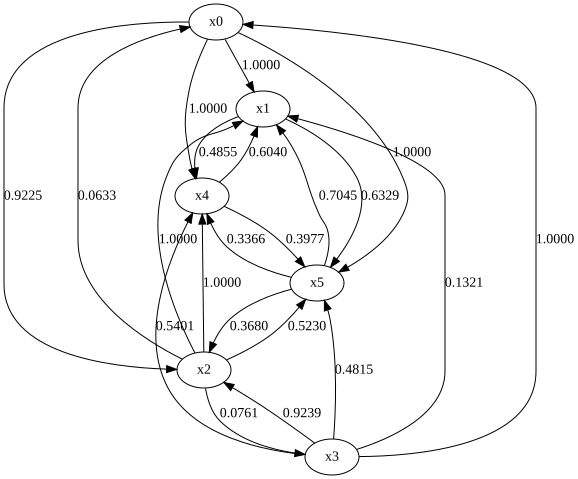

Condition: best


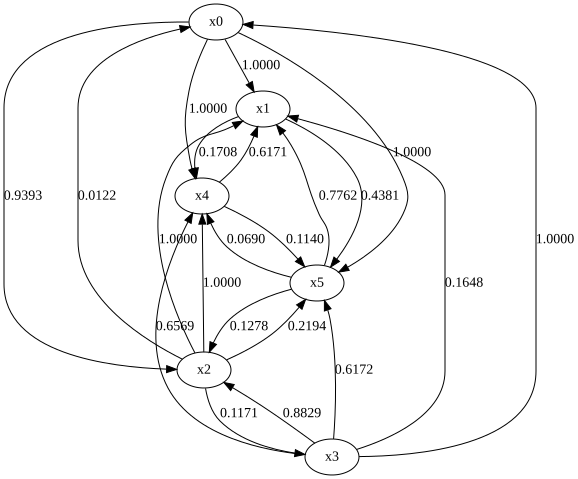

Condition: poly1


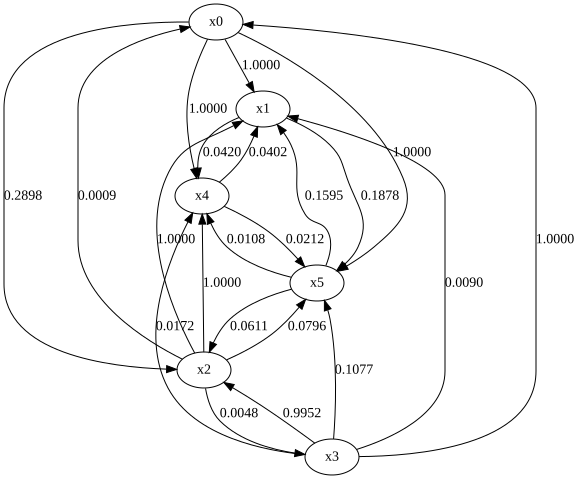

In [18]:
AU_LABEL_FORMAT = "{:.4f}"  # make_dot rounds to 2 digits, so 0.995 or more is shown as 1.00

for condition, result in final_results.items():
    g = graphviz.Digraph(engine="dot")
    for name in variable_names:
        g.node(name)
    for _, row in result[result["hypothesis_type"] == "edge"].iterrows():
        au_pvalue = row["au_pvalue"]
        if np.isnan(au_pvalue) or au_pvalue == 0:
            continue
        source, destination = map(int, row["hypothesis_id"].split(":")[1].split("->"))
        g.edge(variable_names[source], variable_names[destination], label=AU_LABEL_FORMAT.format(au_pvalue))
    # arcs: not output by DirectLiNGAM, kept for models that output bidirected edges
    for _, row in result[result["hypothesis_type"] == "arc"].iterrows():
        au_pvalue = row["au_pvalue"]
        if np.isnan(au_pvalue) or au_pvalue == 0:
            continue
        lower, higher = map(int, row["hypothesis_id"].split(":")[1].split("<->"))
        g.edge(
            variable_names[lower],
            variable_names[higher],
            dir="both",
            style="dashed",
            label=AU_LABEL_FORMAT.format(au_pvalue),
        )
    print(f"Condition: {condition}")
    display(g)


### Whole-graph hypothesis

`graph_states` holds the edge-state matrix (0: no edge, 1: directed edge, 2: bidirected edge; 2 does not appear for `DirectLiNGAM`) of every graph hypothesis. The AU / SI p-values of the graphs of all conditions are put side by side. The edge labels `1.00` in the drawings are only placeholders of a directed edge, not coefficients.

In [19]:
GRAPH_COLUMNS = ["au_pvalue", "si_pvalue"]

graph_comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] == "graph", ["hypothesis_id", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + GRAPH_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in GRAPH_COLUMNS}
    )
    graph_comparison = graph_comparison.merge(part, on="hypothesis_id", validate="one_to_one")

graph_comparison = graph_comparison.sort_values(
    ["au_pvalue_best", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
).reset_index(drop=True)
print(f"{len(graph_comparison)} graph hypotheses")
graph_comparison


59 graph hypotheses


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:b42b2e5ba1e1d53f0007877159071348beb6e65a,0.14,0.704482,0.000000,0.728372,0.0,0.144596,0.0
1,graph:9613778b4caadd18464b3c8d4893b65f66e265cd,0.02,0.426288,0.000000,0.587632,0.0,0.020665,0.0
2,graph:477244c9849ecc7b3898ef131129b8085997d7c8,0.03,0.455837,0.000000,0.517651,0.0,0.070062,0.0
3,graph:1887fc423d7b85242f5b2014d52850890f2dbd89,0.00,0.257893,0.000000,0.366557,0.0,0.003344,0.0
4,graph:0a4f1116447c6d6861ebd6511c667d64225bf7eb,0.02,0.364679,0.000000,0.352777,0.0,0.038882,0.0
5,graph:f6e75e16e60f3f08091f65a9a4984ef583367c0d,0.02,0.214828,0.000000,0.288703,0.0,0.008148,0.0
6,graph:fbbb20cc2775c94b4c25ec01af7b21dc4b6ccadb,0.00,0.183554,0.000000,0.265033,0.0,0.011579,0.0
7,graph:3c067fb96aa76dd14fcd8594bdc6a614e25a47c2,0.07,0.566971,0.000000,0.250533,0.0,0.078573,0.0
8,graph:20c889e3a0c49831e141cddcd9d342cddfb393e1,0.04,0.459041,0.000000,0.178435,0.0,0.054442,0.0
9,graph:8a095c355a07cdecc7461d7171a092b1534f3bee,0.01,0.481897,0.000000,0.156532,0.0,0.023918,0.0


The table is sorted by the AU p-value of the condition `best`, then by BP at `sa` closest to 1. The top graphs are drawn for each condition in descending order of that condition's AU p-value. A graph with a high AU p-value does not always have a high BP.

Condition: ave


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:b42b2e5ba1e1d53f0007877159071348beb6e65a,0.14,0.704482,0.000000,0.728372,0.0,0.144596,0.0
7,graph:3c067fb96aa76dd14fcd8594bdc6a614e25a47c2,0.07,0.566971,0.000000,0.250533,0.0,0.078573,0.0
12,graph:31d2eece55a322f4db21ed41d2979140afdfb890,0.00,0.513299,0.266651,0.096148,0.0,0.005404,0.0
13,graph:5db2d368f554f1694afada7853873125f8a630d8,0.00,0.513299,0.266651,0.096148,0.0,0.005404,0.0
9,graph:8a095c355a07cdecc7461d7171a092b1534f3bee,0.01,0.481897,0.000000,0.156532,0.0,0.023918,0.0


Rank 1: BP=0.140; ave: AU=0.704 SI=0.000, best: AU=0.728 SI=0.000, poly1: AU=0.145 SI=0.000


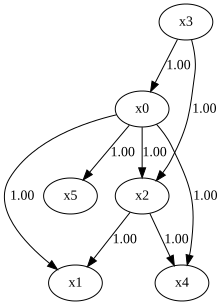

Rank 2: BP=0.070; ave: AU=0.567 SI=0.000, best: AU=0.251 SI=0.000, poly1: AU=0.079 SI=0.000


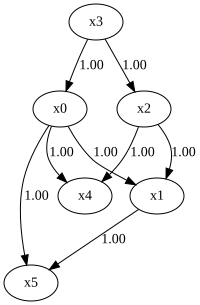

Rank 3: BP=0.000; ave: AU=0.513 SI=0.267, best: AU=0.096 SI=0.000, poly1: AU=0.005 SI=0.000


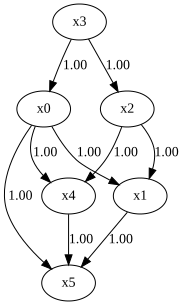

Rank 4: BP=0.000; ave: AU=0.513 SI=0.267, best: AU=0.096 SI=0.000, poly1: AU=0.005 SI=0.000


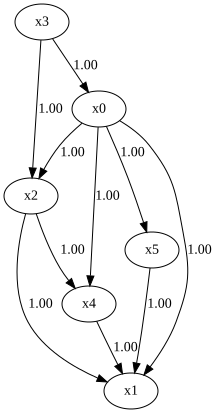

Rank 5: BP=0.010; ave: AU=0.482 SI=0.000, best: AU=0.157 SI=0.000, poly1: AU=0.024 SI=0.000


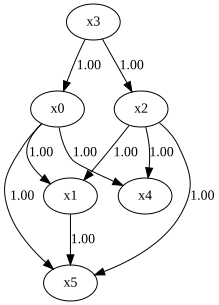

Condition: best


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:b42b2e5ba1e1d53f0007877159071348beb6e65a,0.14,0.704482,0.0,0.728372,0.0,0.144596,0.0
1,graph:9613778b4caadd18464b3c8d4893b65f66e265cd,0.02,0.426288,0.0,0.587632,0.0,0.020665,0.0
2,graph:477244c9849ecc7b3898ef131129b8085997d7c8,0.03,0.455837,0.0,0.517651,0.0,0.070062,0.0
3,graph:1887fc423d7b85242f5b2014d52850890f2dbd89,0.00,0.257893,0.0,0.366557,0.0,0.003344,0.0
4,graph:0a4f1116447c6d6861ebd6511c667d64225bf7eb,0.02,0.364679,0.0,0.352777,0.0,0.038882,0.0


Rank 1: BP=0.140; ave: AU=0.704 SI=0.000, best: AU=0.728 SI=0.000, poly1: AU=0.145 SI=0.000


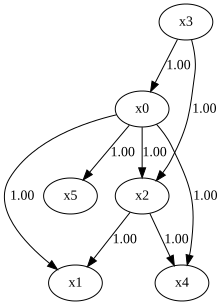

Rank 2: BP=0.020; ave: AU=0.426 SI=0.000, best: AU=0.588 SI=0.000, poly1: AU=0.021 SI=0.000


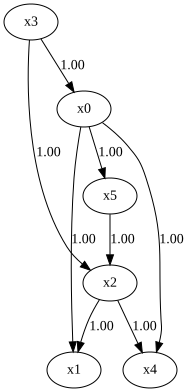

Rank 3: BP=0.030; ave: AU=0.456 SI=0.000, best: AU=0.518 SI=0.000, poly1: AU=0.070 SI=0.000


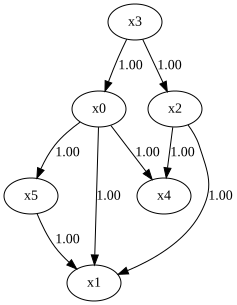

Rank 4: BP=0.000; ave: AU=0.258 SI=0.000, best: AU=0.367 SI=0.000, poly1: AU=0.003 SI=0.000


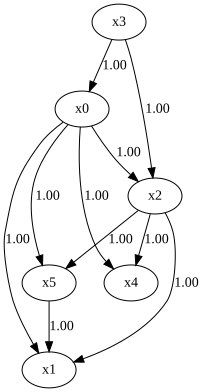

Rank 5: BP=0.020; ave: AU=0.365 SI=0.000, best: AU=0.353 SI=0.000, poly1: AU=0.039 SI=0.000


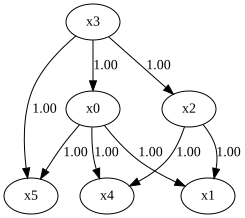

Condition: poly1


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
36,graph:92e02e2435ab022b5a60cb49ca8270b4ce67f61d,0.40,0.033576,0.0,0.026369,0.0,0.405158,0.0
0,graph:b42b2e5ba1e1d53f0007877159071348beb6e65a,0.14,0.704482,0.0,0.728372,0.0,0.144596,0.0
7,graph:3c067fb96aa76dd14fcd8594bdc6a614e25a47c2,0.07,0.566971,0.0,0.250533,0.0,0.078573,0.0
2,graph:477244c9849ecc7b3898ef131129b8085997d7c8,0.03,0.455837,0.0,0.517651,0.0,0.070062,0.0
8,graph:20c889e3a0c49831e141cddcd9d342cddfb393e1,0.04,0.459041,0.0,0.178435,0.0,0.054442,0.0


Rank 1: BP=0.400; ave: AU=0.034 SI=0.000, best: AU=0.026 SI=0.000, poly1: AU=0.405 SI=0.000


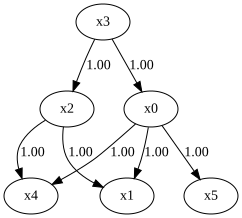

Rank 2: BP=0.140; ave: AU=0.704 SI=0.000, best: AU=0.728 SI=0.000, poly1: AU=0.145 SI=0.000


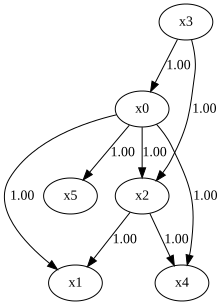

Rank 3: BP=0.070; ave: AU=0.567 SI=0.000, best: AU=0.251 SI=0.000, poly1: AU=0.079 SI=0.000


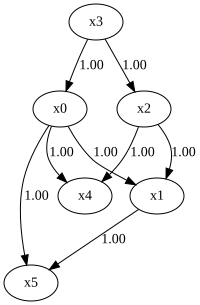

Rank 4: BP=0.030; ave: AU=0.456 SI=0.000, best: AU=0.518 SI=0.000, poly1: AU=0.070 SI=0.000


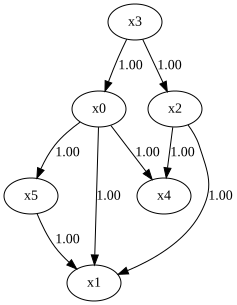

Rank 5: BP=0.040; ave: AU=0.459 SI=0.000, best: AU=0.178 SI=0.000, poly1: AU=0.054 SI=0.000


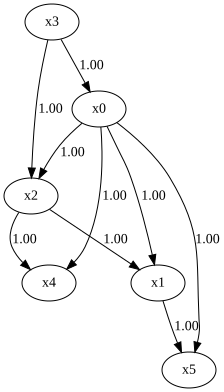

In [20]:
def draw_graph(graph_id):
    state = graph_states[graph_id]
    adjacency = state.astype(float)
    adjacency[state == 2] = np.nan  # bidirected edge
    return make_dot(adjacency, labels=variable_names)


TOP_GRAPH_COUNT = 5

for condition in conditions:
    top_graph_rows = graph_comparison.sort_values(
        [f"au_pvalue_{condition}", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
    ).head(TOP_GRAPH_COUNT)
    print(f"Condition: {condition}")
    display(top_graph_rows)

    for rank, (_, row) in enumerate(top_graph_rows.iterrows(), start=1):
        pvalues = ", ".join(
            f"{c}: AU={row[f'au_pvalue_{c}']:.3f} SI={row[f'si_pvalue_{c}']:.3f}"
            for c in conditions
        )
        print(f"Rank {rank}: BP={row['bp_at_sa1']:.3f}; {pvalues}")
        display(draw_graph(row["hypothesis_id"]))
